# Nonlinear Operator Using Tensor Train Representation

This notebook constructs the nonlinear operator associated with
the Burgers equation.

For the Burgers equation,

    u_t + u u_x = nu u_xx,

the nonlinear term is

    u u_x.

The nonlinear multiplication can be written as

    u u_x = D_u D_x u,

where D_u is the diagonal matrix containing the field values.

The purpose of this notebook is to connect the Tensor Train
representation of the field to this diagonal nonlinear operator.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = np.load("../results/data/burgers_classical_data.npz")

x = data["x"]
times = data["times"]
solutions = data["solutions"]

print("x:", x)
print("times:", times)
print("solutions shape:", solutions.shape)

x: [0.         0.14285714 0.28571429 0.42857143 0.57142857 0.71428571
 0.85714286 1.        ]
times: [0.  0.1 0.2 0.3 0.4 0.5]
solutions shape: (6, 8)


In [3]:
u = solutions[-1]

print("Time =", times[-1])
print("u =", u)

Time = 0.5
u = [0.00000000e+00 1.57767192e-01 3.10550179e-01 4.50815488e-01
 5.62318168e-01 6.00812330e-01 4.50918434e-01 1.22464680e-16]


In [4]:
Du = np.diag(u)

print("D_u =")
print(Du)

D_u =
[[0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 1.57767192e-01 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 3.10550179e-01 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 4.50815488e-01
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  5.62318168e-01 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 6.00812330e-01 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 4.50918434e-01 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 1.22464680

In [5]:
N = len(u)
dx = x[1] - x[0]

Dx = np.zeros((N, N))

for i in range(1, N-1):
    Dx[i, i-1] = -1 / (2*dx)
    Dx[i, i+1] = 1 / (2*dx)


ux = Dx @ u
nonlinear_direct = u * ux

nonlinear_matrix = Du @ Dx @ u

difference = nonlinear_direct - nonlinear_matrix

print("Direct nonlinear term:")
print(nonlinear_direct)

print("\nMatrix nonlinear term:")
print(nonlinear_matrix)

print("\nMaximum difference:")
print(np.max(np.abs(difference)))

Direct nonlinear term:
[ 0.          0.1714812   0.3185217   0.39725318  0.29521082 -0.23425617
 -0.94821074  0.        ]

Matrix nonlinear term:
[ 0.          0.1714812   0.3185217   0.39725318  0.29521082 -0.23425617
 -0.94821074  0.        ]

Maximum difference:
1.1102230246251565e-16


In [6]:
def tt_svd(tensor, max_rank=None, tolerance=1e-12):

    shape = tensor.shape
    d = len(shape)

    cores = []
    ranks = [1]

    current = tensor.copy()

    for k in range(d - 1):

        r_prev = ranks[-1]
        n_k = shape[k]

        # Reshape tensor into a matrix
        current = current.reshape(
            r_prev * n_k,
            -1
        )

        # Singular Value Decomposition
        U, S, Vt = np.linalg.svd(
            current,
            full_matrices=False
        )

        # Determine rank
        if max_rank is not None:
            rank = min(max_rank, len(S))
        else:
            rank = len(S)

        # Truncate
        U = U[:, :rank]
        S = S[:rank]
        Vt = Vt[:rank, :]

        # Create TT core
        core = U.reshape(
            r_prev,
            n_k,
            rank
        )

        cores.append(core)

        # Pass remaining part to next step
        current = np.diag(S) @ Vt

        ranks.append(rank)

    # Final TT core
    final_core = current.reshape(
        ranks[-1],
        shape[-1],
        1
    )

    cores.append(final_core)
    ranks.append(1)

    return cores, ranks



u_tensor = u.reshape(2, 2, 2)

cores, ranks = tt_svd(
    u_tensor,
    max_rank=2
)

print("TT ranks:", ranks)

for i, core in enumerate(cores):
    print(f"Core {i+1} shape:", core.shape)

TT ranks: [1, 2, 2, 1]
Core 1 shape: (1, 2, 2)
Core 2 shape: (2, 2, 2)
Core 3 shape: (2, 2, 1)


In [7]:
def tt_reconstruct(cores):

    result = cores[0]

    for core in cores[1:]:

        result = np.tensordot(
            result,
            core,
            axes=([-1], [0])
        )

    return np.squeeze(result)


u_tensor_tt = tt_reconstruct(cores)

u_tt = u_tensor_tt.reshape(-1)

print("Original u:")
print(u)

print("\nTT reconstructed u:")
print(u_tt)

Original u:
[0.00000000e+00 1.57767192e-01 3.10550179e-01 4.50815488e-01
 5.62318168e-01 6.00812330e-01 4.50918434e-01 1.22464680e-16]

TT reconstructed u:
[9.93421868e-17 1.57767192e-01 3.10550179e-01 4.50815488e-01
 5.62318168e-01 6.00812330e-01 4.50918434e-01 2.73700128e-17]


In [8]:
tt_error = (
    np.linalg.norm(u - u_tt)
    /
    np.linalg.norm(u)
)

print("TT relative L2 error:", tt_error)

TT relative L2 error: 3.8969111853292715e-16


In [9]:
Du_tt = np.diag(u_tt)

print("Diagonal TT-based operator:")
print(Du_tt)

nonlinear_tt = Du_tt @ Dx @ u

nonlinear_exact = Du @ Dx @ u

error_nonlinear = (
    np.linalg.norm(nonlinear_exact - nonlinear_tt)
    /
    np.linalg.norm(nonlinear_exact)
)

print("Relative nonlinear-term error:")
print(error_nonlinear)

Diagonal TT-based operator:
[[9.93421868e-17 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 1.57767192e-01 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 3.10550179e-01 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 4.50815488e-01
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  5.62318168e-01 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 6.00812330e-01 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 4.50918434e-01 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.0

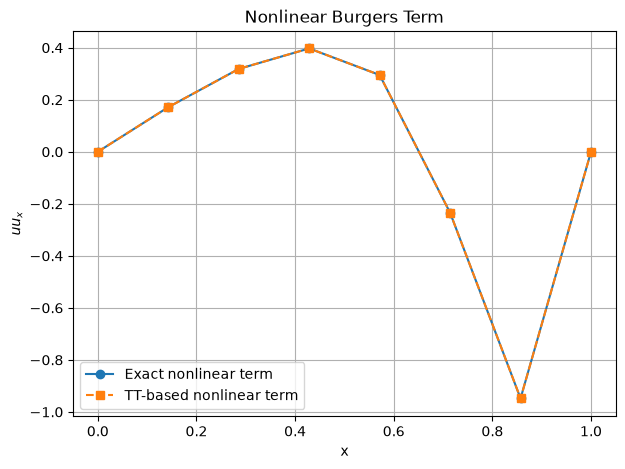

In [10]:
plt.figure(figsize=(7,5))

plt.plot(
    x,
    nonlinear_exact,
    'o-',
    label="Exact nonlinear term"
)

plt.plot(
    x,
    nonlinear_tt,
    's--',
    label="TT-based nonlinear term"
)

plt.xlabel("x")
plt.ylabel(r"$u u_x$")
plt.title("Nonlinear Burgers Term")

plt.legend()
plt.grid(True)

plt.show()

In [11]:
D_tt_explicit = np.diag(u_tt)

print("Shape:", D_tt_explicit.shape)
print(D_tt_explicit)

Shape: (8, 8)
[[9.93421868e-17 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 1.57767192e-01 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 3.10550179e-01 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 4.50815488e-01
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  5.62318168e-01 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 6.00812330e-01 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 4.50918434e-01 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 2.

In [12]:

off_diagonal = D_tt_explicit - np.diag(
    np.diag(D_tt_explicit)
)

print(
    "Maximum off-diagonal value:",
    np.max(np.abs(off_diagonal))
)



Maximum off-diagonal value: 0.0


In [13]:
v = np.random.rand(N)
result_matrix = D_tt_explicit @ v
result_elementwise = u_tt * v

print(
    "Maximum difference:",
    np.max(
        np.abs(
            result_matrix - result_elementwise
        )
    )
)

Maximum difference: 0.0


In [14]:
ux = Dx @ u

nonlinear_from_operator = D_tt_explicit @ ux

nonlinear_elementwise = u_tt * ux

print(
    "Maximum difference:",
    np.max(
        np.abs(
            nonlinear_from_operator
            -
            nonlinear_elementwise
        )
    )
)

Maximum difference: 0.0


In [15]:
nonlinear_exact = u * ux

nonlinear_approx = u_tt * ux

nonlinear_error = (
    np.linalg.norm(
        nonlinear_exact - nonlinear_approx
    )
    /
    np.linalg.norm(nonlinear_exact)
)

print(
    "Relative nonlinear-term error:",
    nonlinear_error
)

Relative nonlinear-term error: 5.014201493459145e-16


In [16]:
bond_dimensions = [1, 2, 3, 4]

nonlinear_errors = []

for chi in bond_dimensions:

    cores, ranks = tt_svd(
        u_tensor,
        max_rank=chi
    )

    reconstructed_tensor = tt_reconstruct(cores)

    u_tt = reconstructed_tensor.reshape(-1)

    nonlinear_exact = u * ux
    nonlinear_approx = u_tt * ux

    error = (
        np.linalg.norm(
            nonlinear_exact - nonlinear_approx
        )
        /
        np.linalg.norm(nonlinear_exact)
    )

    nonlinear_errors.append(error)

    print(
        f"chi = {chi}, "
        f"ranks = {ranks}, "
        f"nonlinear error = {error:.6e}"
    )

chi = 1, ranks = [1, 1, 1, 1], nonlinear error = 3.431673e-01
chi = 2, ranks = [1, 2, 2, 1], nonlinear error = 5.014201e-16
chi = 3, ranks = [1, 2, 2, 1], nonlinear error = 5.014201e-16
chi = 4, ranks = [1, 2, 2, 1], nonlinear error = 5.014201e-16


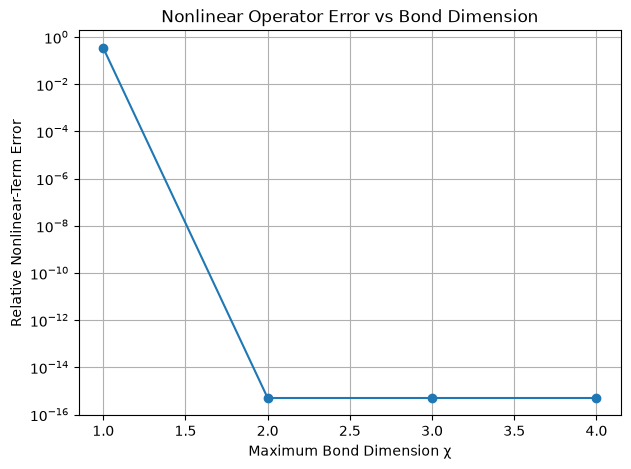

In [17]:
plt.figure(figsize=(7,5))

plt.semilogy(
    bond_dimensions,
    nonlinear_errors,
    'o-'
)

plt.xlabel("Maximum Bond Dimension χ")
plt.ylabel("Relative Nonlinear-Term Error")
plt.title("Nonlinear Operator Error vs Bond Dimension")

plt.grid(True)

plt.show()

In [18]:
beta_diag = np.max(np.abs(u_tt))

print("Diagonal operator normalization:", beta_diag)

Diagonal operator normalization: 0.6008123299171804


In [19]:
D_normalized = D_tt_explicit / beta_diag

print(D_normalized)

[[1.65346452e-16 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 2.62589804e-01 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 5.16883832e-01 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 7.50343270e-01
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  9.35929807e-01 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 1.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 7.50514614e-01 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 4.55550118e-17]]

In [20]:
print(
    "Maximum absolute diagonal:",
    np.max(np.abs(np.diag(D_normalized)))
)

Maximum absolute diagonal: 1.0


In [21]:
for j, t in enumerate(times):

    u_current = solutions[j]

    tensor = u_current.reshape(2, 2, 2)

    cores, ranks = tt_svd(
        tensor,
        max_rank=2
    )

    reconstructed = tt_reconstruct(cores)
    u_tt = reconstructed.reshape(-1)

    Du_tt = np.diag(u_tt)

    print(
        f"t = {t:.1f}, "
        f"max|u| = {np.max(np.abs(u_tt)):.6f}"
    )

t = 0.0, max|u| = 0.974928
t = 0.1, max|u| = 0.909837
t = 0.2, max|u| = 0.811915
t = 0.3, max|u| = 0.741108
t = 0.4, max|u| = 0.671317
t = 0.5, max|u| = 0.600812
